# NVAE: Deep Hierarchical VAE (Teaching Implementation)

NVAE is a deep, multiscale hierarchical VAE with many latent groups and careful engineering. This notebook implements a compact hierarchical teaching model for the main idea, not a full NVAE reproduction.

This standalone notebook includes its own MNIST setup, model components, objective, and training step. Run the cells from top to bottom. The training cell runs 50 epochs on the full MNIST training split. A GPU runtime is recommended in Colab.

## Shared MNIST data and VAE components

The baseline is a small MLP VAE with a diagonal Gaussian posterior and Bernoulli image decoder. We reuse it where the variant changes the objective rather than the architecture.

In [1]:
import math
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
transform = transforms.ToTensor()
train_data = datasets.MNIST('data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)

class MLPVAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__(); self.latent_dim = latent_dim
        self.encoder = nn.Sequential(nn.Linear(784, 400), nn.ReLU())
        self.mu = nn.Linear(400, latent_dim); self.logvar = nn.Linear(400, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 400), nn.ReLU(), nn.Linear(400, 784), nn.Sigmoid())
    def encode(self, x):
        h = self.encoder(x.flatten(1)); return self.mu(h), self.logvar(h)
    def reparameterize(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)
    def forward(self, x):
        mu, logvar = self.encode(x); z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

def vae_terms(recon, x, mu, logvar):
    rec = F.binary_cross_entropy(recon, x, reduction='none').flatten(1).sum(1).mean()
    kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum(1).mean()
    return rec, kl

def sample_batch(loader):
    return next(iter(loader))[0].to(device)

Using device: cuda


## Implementation

The following cell defines this variant's model-specific objective and optimization step.

## 6. Compact NVAE-style multiscale hierarchical VAE

NVAE is a deep convolutional hierarchical VAE with many latent groups, residual blocks, and careful numerical techniques. A faithful implementation is a substantial project. The following small model is a runnable teaching example of the central idea: a top latent prior conditions a lower latent prior, and both spatial latent groups contribute to image reconstruction. It is not a reproduction of NVAE or its published performance.

In [2]:
class TinyMultiscaleVAE(nn.Module):
    def __init__(self, z_top=8, z_bottom=16):
        super().__init__(); self.z_top, self.z_bottom = z_top, z_bottom
        self.enc = nn.Sequential(nn.Conv2d(1, 32, 4, 2, 1), nn.ReLU(), nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU())  # 7x7
        self.top_mu = nn.Conv2d(64, z_top, 1); self.top_lv = nn.Conv2d(64, z_top, 1)
        self.prior_bottom = nn.Sequential(nn.Conv2d(z_top, 32, 3, padding=1), nn.ReLU())
        self.prior_mu = nn.Conv2d(32, z_bottom, 1); self.prior_lv = nn.Conv2d(32, z_bottom, 1)
        self.bottom_mu = nn.Conv2d(64 + z_top, z_bottom, 1); self.bottom_lv = nn.Conv2d(64 + z_top, z_bottom, 1)
        self.dec = nn.Sequential(nn.Conv2d(z_top + z_bottom, 64, 3, padding=1), nn.ReLU(), nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Sigmoid())
    @staticmethod
    def sample(mu, lv): return mu + torch.exp(.5 * lv) * torch.randn_like(mu)
    def forward(self, x):
        h = self.enc(x); mu_t, lv_t = self.top_mu(h), self.top_lv(h); zt = self.sample(mu_t, lv_t)
        prior_h = self.prior_bottom(zt); mu_p, lv_p = self.prior_mu(prior_h), self.prior_lv(prior_h)
        bottom_input = torch.cat([h, zt], dim=1); mu_b, lv_b = self.bottom_mu(bottom_input), self.bottom_lv(bottom_input)
        zb = self.sample(mu_b, lv_b); recon = self.dec(torch.cat([zt, zb], dim=1))
        return recon, (mu_t, lv_t, mu_b, lv_b, mu_p, lv_p)

def spatial_kl(mu_q, lv_q, mu_p=None, lv_p=None):
    if mu_p is None: mu_p, lv_p = torch.zeros_like(mu_q), torch.zeros_like(lv_q)
    term = lv_p - lv_q + (torch.exp(lv_q) + (mu_q - mu_p).square()) * torch.exp(-lv_p) - 1
    return .5 * term.sum(dim=1).mean()

nvae_toy = TinyMultiscaleVAE().to(device); nvae_optim = torch.optim.Adam(nvae_toy.parameters(), lr=1e-3)

def tiny_nvae_train_step(x):
    x = x.to(device); recon, (mt, lt, mb, lb, mp, lp) = nvae_toy(x)
    rec = F.binary_cross_entropy(recon, x); kl_top = spatial_kl(mt, lt); kl_bottom = spatial_kl(mb, lb, mp, lp)
    loss = rec + kl_top + kl_bottom
    nvae_optim.zero_grad(); loss.backward(); nvae_optim.step()
    return {'reconstruction': rec.item(), 'kl_top': kl_top.item(), 'kl_bottom': kl_bottom.item()}

# Example: metrics = tiny_nvae_train_step(sample_batch(train_loader))

## Full training — 50 epochs

This runs on the full MNIST training split using the model-specific objective above. In Colab, select a GPU runtime for faster training. The final checkpoint includes model weights, optimizer state, and epoch metrics.

In [3]:
from pathlib import Path

epochs = 50
history = []
for epoch in range(1, epochs + 1):
    totals = {}
    for images, _ in train_loader:
        batch_metrics = tiny_nvae_train_step(images)
        for name, value in batch_metrics.items():
            totals[name] = totals.get(name, 0.0) + float(value) * images.size(0)
    epoch_metrics = {name: value / len(train_loader.dataset) for name, value in totals.items()}
    history.append(epoch_metrics)
    summary = " | ".join(f"{name}={value:.4f}" for name, value in epoch_metrics.items())
    print(f"Epoch {epoch:02d}/{epochs} | {summary}")

checkpoint = {
    "model": nvae_toy.state_dict(),
    "optimizers": {"nvae_optim": nvae_optim.state_dict()},
    "epochs": epochs,
    "history": history
}
checkpoint_path = Path("14_NVAE_50_epochs.pt")
torch.save(checkpoint, checkpoint_path)
print(f"Saved checkpoint to {checkpoint_path.resolve()}")


Epoch 01/50 | reconstruction=0.3468 | kl_top=0.0026 | kl_bottom=0.0472
Epoch 02/50 | reconstruction=0.2793 | kl_top=0.0001 | kl_bottom=0.0008
Epoch 03/50 | reconstruction=0.2747 | kl_top=0.0000 | kl_bottom=0.0002
Epoch 04/50 | reconstruction=0.2740 | kl_top=0.0000 | kl_bottom=0.0001
Epoch 05/50 | reconstruction=0.2738 | kl_top=0.0000 | kl_bottom=0.0001
Epoch 06/50 | reconstruction=0.2737 | kl_top=0.0000 | kl_bottom=0.0001
Epoch 07/50 | reconstruction=0.2736 | kl_top=0.0000 | kl_bottom=0.0001
Epoch 08/50 | reconstruction=0.2735 | kl_top=0.0000 | kl_bottom=0.0001
Epoch 09/50 | reconstruction=0.2734 | kl_top=0.0000 | kl_bottom=0.0001
Epoch 10/50 | reconstruction=0.2734 | kl_top=0.0000 | kl_bottom=0.0001
Epoch 11/50 | reconstruction=0.2734 | kl_top=0.0000 | kl_bottom=0.0001
Epoch 12/50 | reconstruction=0.2734 | kl_top=0.0000 | kl_bottom=0.0001
Epoch 13/50 | reconstruction=0.2733 | kl_top=0.0000 | kl_bottom=0.0001
Epoch 14/50 | reconstruction=0.2733 | kl_top=0.0000 | kl_bottom=0.0001
Epoch 

## Inspect multiscale reconstructions and top-down samples

Use these plots alongside the objective metrics; no single number captures reconstruction quality, prior matching, latent use, and sample quality.

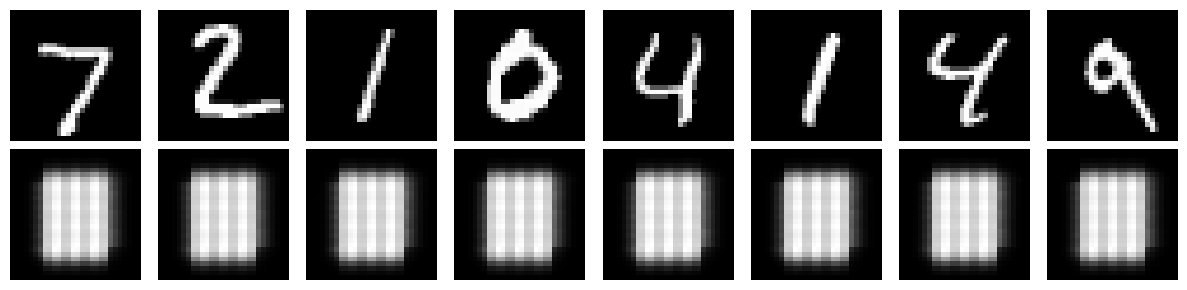

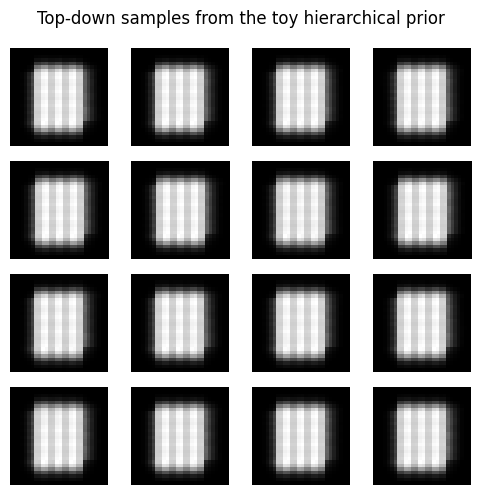

Example top KL: 0.00; bottom conditional KL: 0.00


In [4]:
x = sample_batch(test_loader)[:8]
nvae_toy.eval()
with torch.no_grad():
    recon, (mu_t, lv_t, mu_b, lv_b, mu_p, lv_p) = nvae_toy(x)
    zt = torch.randn(16, nvae_toy.z_top, 7, 7, device=device)
    hp = nvae_toy.prior_bottom(zt); mup, lvp = nvae_toy.prior_mu(hp), nvae_toy.prior_lv(hp)
    zb = nvae_toy.sample(mup, lvp)
    prior_samples = nvae_toy.dec(torch.cat([zt, zb], dim=1))
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(x[i, 0].cpu(), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(recon[i, 0].cpu(), cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_ylabel('Input'); axes[1, 0].set_ylabel('Reconstruction')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(4, 4, figsize=(5, 5))
for ax, image in zip(axes.flat, prior_samples):
    ax.imshow(image[0].cpu(), cmap='gray'); ax.axis('off')
plt.suptitle('Top-down samples from the toy hierarchical prior'); plt.tight_layout(); plt.show()
print(f'Example top KL: {spatial_kl(mu_t, lv_t).item():.2f}; bottom conditional KL: {spatial_kl(mu_b, lv_b, mu_p, lv_p).item():.2f}')